In [47]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# importing necessary libraries

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# importing data from sources

In [49]:
dataset=pd.read_csv('/content/drive/MyDrive/Heart_disease_statlog.csv')

In [50]:
dataset

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,2,172,199,1,0,162,0,0.5,0,0,3,0
266,44,1,1,120,263,0,0,173,0,0.0,0,0,3,0
267,56,0,1,140,294,0,2,153,0,1.3,1,0,1,0
268,57,1,3,140,192,0,0,148,0,0.4,1,0,2,0


In [51]:
print(dataset['sex'].unique())

[1 0]


In [52]:
dataset['sex'] = dataset['sex'].astype(str)

In [53]:
dataset['sex'].dtype
dataset['sex']=dataset['sex'].map({'1':'male', '0':'female'})
dataset

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,male,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,female,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,male,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,male,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,female,1,120,269,0,2,121,1,0.2,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,male,2,172,199,1,0,162,0,0.5,0,0,3,0
266,44,male,1,120,263,0,0,173,0,0.0,0,0,3,0
267,56,female,1,140,294,0,2,153,0,1.3,1,0,1,0
268,57,male,3,140,192,0,0,148,0,0.4,1,0,2,0


In [54]:
dataset['sex'].dtype
dataset['sex']=dataset['sex'].map({'male':'1', 'female':'0'})
dataset

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,52,1,2,172,199,1,0,162,0,0.5,0,0,3,0
266,44,1,1,120,263,0,0,173,0,0.0,0,0,3,0
267,56,0,1,140,294,0,2,153,0,1.3,1,0,1,0
268,57,1,3,140,192,0,0,148,0,0.4,1,0,2,0


In [55]:
print(dataset['sex'].unique())

['1' '0']


# clean and preprocess the data

In [56]:
dataset.duplicated().sum()

np.int64(0)

In [57]:
#checking for null data
dataset.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


# performing EDA

In [58]:
target_positive=dataset[dataset['target']==1]
target_positive

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
6,56,1,2,130,256,1,2,142,1,0.6,1,1,2,1
7,59,1,3,110,239,0,2,142,1,1.2,1,1,3,1
8,60,1,3,140,293,0,2,170,0,1.2,1,2,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
258,64,1,2,140,335,0,0,158,0,0.0,0,0,1,1
261,60,1,3,130,206,0,2,132,1,2.4,1,2,3,1
262,58,1,1,120,284,0,2,160,0,1.8,1,0,1,1
264,48,1,1,110,229,0,0,168,0,1.0,2,0,3,1


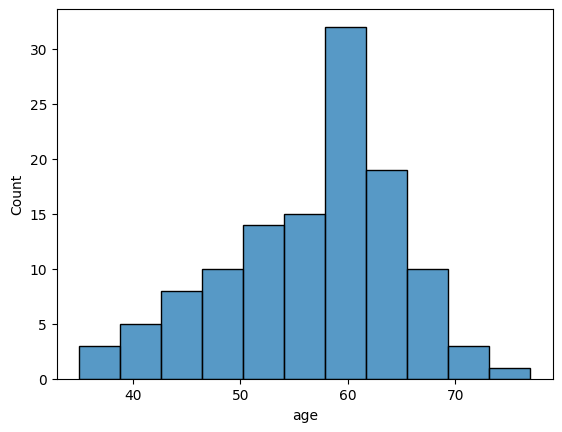

In [59]:
sns.histplot(data=target_positive, x='age')
plt.show()

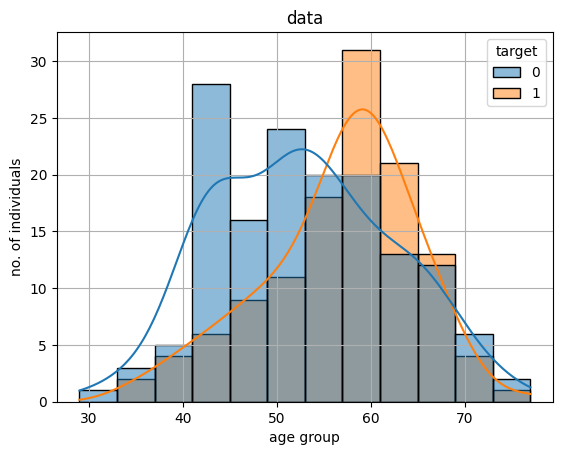

In [60]:
import matplotlib.pyplot as plt
import importlib

importlib.reload(plt)
target_positive=dataset[dataset['target']==1]
target_negative=dataset[dataset['target']==0]
sns.histplot(data=dataset, x='age', hue='target', kde=True)
plt.title("data")
plt.xlabel("age group")
plt.ylabel("no. of individuals")
plt.grid(True)
plt.show()

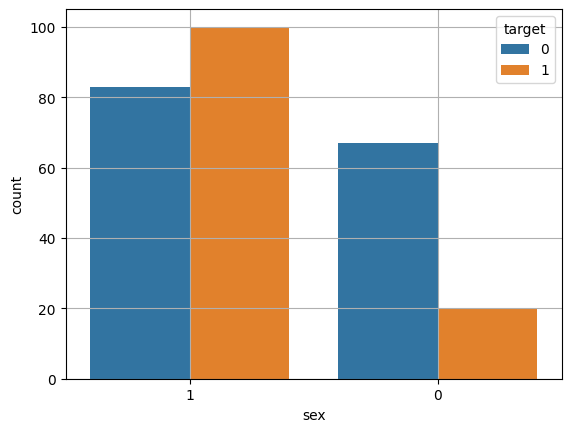

In [61]:
sns.countplot(data=dataset, x='sex', hue='target')
plt.xlabel=("sex")
plt.ylabel=("no. of individuals")
plt.grid(True)
plt.show()

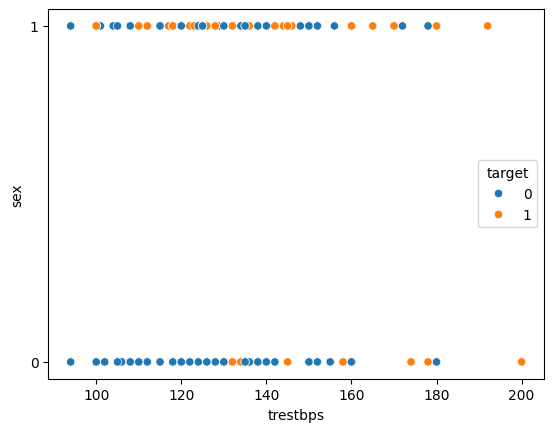

In [62]:
sns.scatterplot(data=dataset, x='trestbps', y='sex', hue='target', )
plt.show()

In [63]:
#correlational Matrix (positive and negative)
dataset_corr=dataset.corr()
dataset_corr

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.094401,0.096920,0.273053,0.220056,0.123458,0.128171,-0.402215,0.098297,0.194234,0.159774,0.356081,0.099055,0.212322
sex,-0.094401,1.000000,0.034636,-0.062693,-0.201647,0.042140,0.039253,-0.076101,0.180022,0.097412,0.050545,0.086830,0.376936,0.297721
cp,0.096920,0.034636,1.000000,-0.043196,0.090465,-0.098537,0.074325,-0.317682,0.353160,0.167244,0.136900,0.225890,0.266614,0.417436
trestbps,0.273053,-0.062693,-0.043196,1.000000,0.173019,0.155681,0.116157,-0.039136,0.082793,0.222800,0.142472,0.085697,0.127273,0.155383
chol,0.220056,-0.201647,0.090465,0.173019,1.000000,0.025186,0.167652,-0.018739,0.078243,0.027709,-0.005755,0.126541,0.040317,0.118021
fbs,0.123458,0.042140,-0.098537,0.155681,0.025186,1.000000,0.053499,0.022494,-0.004107,-0.025538,0.044076,0.123774,0.044770,-0.016319
restecg,0.128171,0.039253,0.074325,0.116157,0.167652,0.053499,1.000000,-0.074628,0.095098,0.120034,0.160614,0.114368,0.004143,0.182091
thalach,-0.402215,-0.076101,-0.317682,-0.039136,-0.018739,0.022494,-0.074628,1.000000,-0.380719,-0.349045,-0.386847,-0.265333,-0.241003,-0.418514
exang,0.098297,0.180022,0.353160,0.082793,0.078243,-0.004107,0.095098,-0.380719,1.000000,0.274672,0.255908,0.153347,0.319499,0.419303
oldpeak,0.194234,0.097412,0.167244,0.222800,0.027709,-0.025538,0.120034,-0.349045,0.274672,1.000000,0.609712,0.255005,0.325240,0.417967


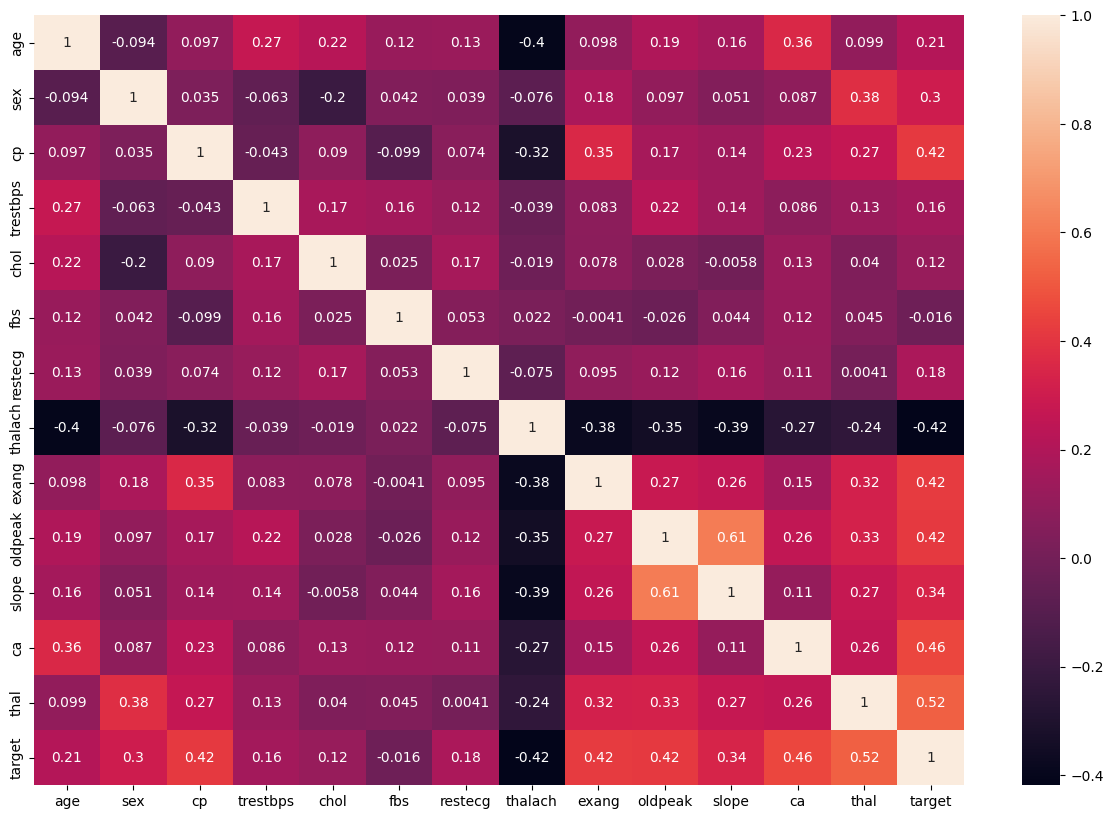

In [64]:
plt.figure(figsize=(15, 10))
sns.heatmap(dataset_corr, annot=True)
plt.show()

# Data preparing for model training

In [65]:
Y= dataset['target']
X= dataset.drop('target',axis=1)

In [66]:
Y

,target
0,1
1,0
2,1
3,0
4,0
...,...
265,0
266,0
267,0
268,0


In [67]:
from sklearn.preprocessing import StandardScaler

#performing feature scaling

from sklearn.model_selection import train_test_split

# Split the dataset BEFORE scaling
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (216, 13)
Testing data: (54, 13)


In [68]:

from sklearn.preprocessing import StandardScaler

# Feature scaling
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Scaling completed successfully!")


Scaling completed successfully!


#Model Training(Classificational Problem)

DecisionTreeClassifier

In [69]:
dtc_model=DecisionTreeClassifier(random_state=42)
dtc_model.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [70]:
dtc_model_prediction= dtc_model.predict(X_test)
dtc_model_prediction


array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 1])

In [71]:
print(classification_report(y_test, dtc_model_prediction))

              precision    recall  f1-score   support

           0       0.85      0.77      0.81        30
           1       0.74      0.83      0.78        24

    accuracy                           0.80        54
   macro avg       0.80      0.80      0.80        54
weighted avg       0.80      0.80      0.80        54



logistic regression

In [72]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=2000)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [73]:
logistic_model_prediction=logistic_model.predict(X_test_scaled)
logistic_model_prediction

array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 1])

In [74]:
print(classification_report(y_test, logistic_model_prediction))

              precision    recall  f1-score   support

           0       0.92      0.80      0.86        30
           1       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54



In [75]:
dataset.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [76]:
data=np.array([[25, 1, 3, 125, 110, 1, 5, 89, 1, 3.3, 0, 5, 0]])
data

array([[ 25. ,   1. ,   3. , 125. , 110. ,   1. ,   5. ,  89. ,   1. ,
          3.3,   0. ,   5. ,   0. ]])

In [77]:
import pandas as pd

data = pd.DataFrame(
    [[25, 1, 3, 125, 110, 1, 5, 89, 1, 3.3, 0, 5, 0]],
    columns=X_train.columns
)

scaled_data = scaler.transform(data)

prediction = logistic_model.predict(scaled_data)

print("Prediction:", prediction)

Prediction: [1]


In [78]:
logistic_model.predict(scaled_data)

array([1])

*RandomForestClassifier

In [79]:
from sklearn.ensemble import RandomForestClassifier

rfc_model=RandomForestClassifier(random_state=42)
rfc_model.fit(X_train,y_train)

RandomForestClassifier(random_state=42)

In [80]:
rfc_model_prediction=rfc_model.predict(X_test)
rfc_model_prediction

array([0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 0, 0, 1, 1, 0, 1, 1, 0, 1])

In [81]:
print(classification_report(y_test, rfc_model_prediction))

              precision    recall  f1-score   support

           0       0.86      0.80      0.83        30
           1       0.77      0.83      0.80        24

    accuracy                           0.81        54
   macro avg       0.81      0.82      0.81        54
weighted avg       0.82      0.81      0.82        54



In [82]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Prepare scaled test data for Logistic Regression
X_test_scaled = scaler.transform(X_test)

# Predictions
logistic_predictions = logistic_model.predict(X_test_scaled)
rf_predictions = rfc_model.predict(X_test)

# Compare models
print("LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_test, logistic_predictions))
print(classification_report(y_test, logistic_predictions))
print("Confusion Matrix:\n",
      confusion_matrix(y_test, logistic_predictions))

print("\nRANDOM FOREST")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print(classification_report(y_test, rf_predictions))
print("Confusion Matrix:\n",
      confusion_matrix(y_test, rf_predictions))


LOGISTIC REGRESSION
Accuracy: 0.8518518518518519
              precision    recall  f1-score   support

           0       0.92      0.80      0.86        30
           1       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54

Confusion Matrix:
 [[24  6]
 [ 2 22]]

RANDOM FOREST
Accuracy: 0.8148148148148148
              precision    recall  f1-score   support

           0       0.86      0.80      0.83        30
           1       0.77      0.83      0.80        24

    accuracy                           0.81        54
   macro avg       0.81      0.82      0.81        54
weighted avg       0.82      0.81      0.82        54

Confusion Matrix:
 [[24  6]
 [ 4 20]]


In [83]:

logistic_probability = logistic_model.predict_proba(X_test_scaled)[:, 1]
rf_probability = rfc_model.predict_proba(X_test)[:, 1]

print("Logistic Regression ROC-AUC:",
      roc_auc_score(y_test, logistic_probability))

print("Random Forest ROC-AUC:",
      roc_auc_score(y_test, rf_probability))


Logistic Regression ROC-AUC: 0.898611111111111
Random Forest ROC-AUC: 0.8680555555555556


In [84]:
from sklearn.metrics import accuracy_score, roc_auc_score

# Logistic Regression
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, logistic_model_prediction))

# Decision Tree
print("Decision Tree Accuracy:",
      accuracy_score(y_test, dtc_model_prediction))

# Random Forest
print("Random Forest Accuracy:",
      accuracy_score(y_test, rfc_model_prediction))

Logistic Regression Accuracy: 0.8518518518518519
Decision Tree Accuracy: 0.7962962962962963
Random Forest Accuracy: 0.8148148148148148


In [85]:
from sklearn.metrics import classification_report, confusion_matrix

print("LOGISTIC REGRESSION RESULTS")

print(classification_report(y_test, logistic_model_prediction))

print("Confusion Matrix:")
print(confusion_matrix(y_test, logistic_model_prediction))

LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

           0       0.92      0.80      0.86        30
           1       0.79      0.92      0.85        24

    accuracy                           0.85        54
   macro avg       0.85      0.86      0.85        54
weighted avg       0.86      0.85      0.85        54

Confusion Matrix:
[[24  6]
 [ 2 22]]


In [86]:
import joblib

model_data = {
    "model": logistic_model,
    "scaler": scaler,
    "features": list(X_train.columns)
}

joblib.dump(model_data, "heart_disease_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [87]:
from google.colab import files

files.download("heart_disease_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [88]:
for c in ['cp','restecg','slope','ca','thal']:
    print(c, sorted(dataset[c].unique()))

cp [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
restecg [np.int64(0), np.int64(1), np.int64(2)]
slope [np.int64(0), np.int64(1), np.int64(2)]
ca [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
thal [np.int64(1), np.int64(2), np.int64(3)]


In [89]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_models = {
    "Logistic": LogisticRegression(max_iter=2000),
    "RandomForest": RandomForestClassifier(random_state=42),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
}
for name, m in cv_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", m)])
    s = cross_val_score(pipe, X.astype(float), Y, cv=cv, scoring="roc_auc")
    print(f"{name}: CV AUC {s.mean():.3f} +/- {s.std():.3f}")

Logistic: CV AUC 0.896 +/- 0.044
RandomForest: CV AUC 0.877 +/- 0.049
DecisionTree: CV AUC 0.719 +/- 0.063


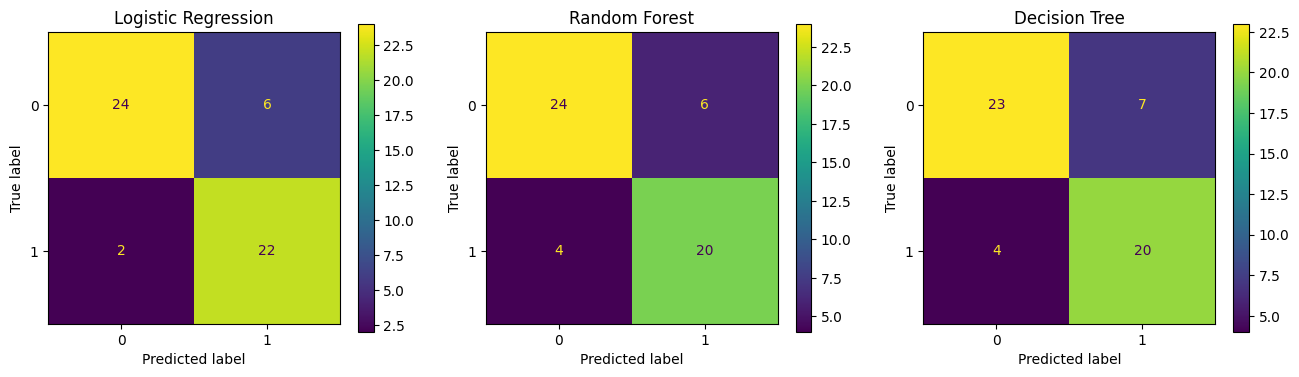

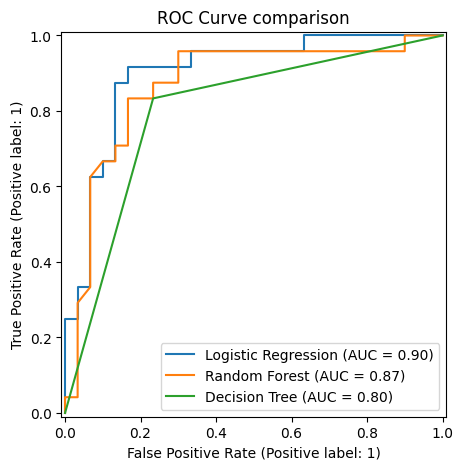

In [90]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

eval_sets = {
    "Logistic Regression": (logistic_model, X_test_scaled),
    "Random Forest": (rfc_model, X_test),
    "Decision Tree": (dtc_model, X_test),
}

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (name, (m, Xt)) in zip(ax, eval_sets.items()):
    ConfusionMatrixDisplay.from_estimator(m, Xt, y_test, ax=a)
    a.set_title(name)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, (m, Xt) in eval_sets.items():
    RocCurveDisplay.from_estimator(m, Xt, y_test, ax=ax, name=name)
plt.title("ROC Curve comparison")
plt.show()

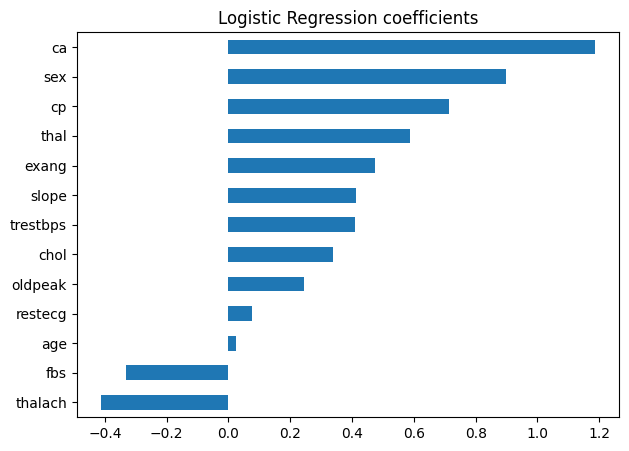

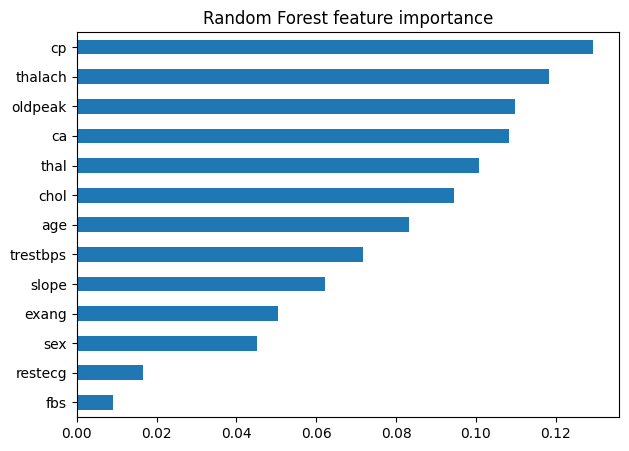

In [91]:
coef = pd.Series(logistic_model.coef_[0], index=X_train.columns).sort_values()
coef.plot(kind="barh", figsize=(7, 5), title="Logistic Regression coefficients")
plt.show()

rf_imp = pd.Series(rfc_model.feature_importances_, index=X_train.columns).sort_values()
rf_imp.plot(kind="barh", figsize=(7, 5), title="Random Forest feature importance")
plt.show()

## Conclusion

I compared three classifiers (Decision Tree, Random Forest, Logistic Regression) on
the Statlog heart disease dataset (270 patients, 13 features) using a held-out test
set and 5-fold cross-validation.

**Best model: Logistic Regression**
- 5-fold CV ROC-AUC: 0.896 (±0.044), vs Random Forest 0.877 and Decision Tree 0.719
- Test accuracy 0.85, ROC-AUC 0.90
- Disease recall 0.92: it caught 22 of 24 patients with heart disease (2 missed)
- Precision for disease 0.79: 6 healthy patients were flagged as at risk

**Why Logistic Regression:** its CV score was slightly higher than Random Forest
(the gap is within one standard deviation, so they are close), and it is simple,
fast and interpretable. The coefficients show `ca`, `sex`, `cp` and `thal` as the
strongest predictors.

**Why recall matters:** in a medical screening setting, missing a patient with
disease (false negative) is costlier than a false alarm, so I looked at recall
and not just accuracy.

**Limitations:** only 270 rows and a 54-sample test set, so results are noisy;
a single dataset; not validated clinically. This is an educational project, not
a medical tool.

**Next steps:** threshold tuning to push recall higher, SHAP explanations, and
testing on a larger dataset.